ML environment ready
Shape (rows, columns): (6607, 20)
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence     

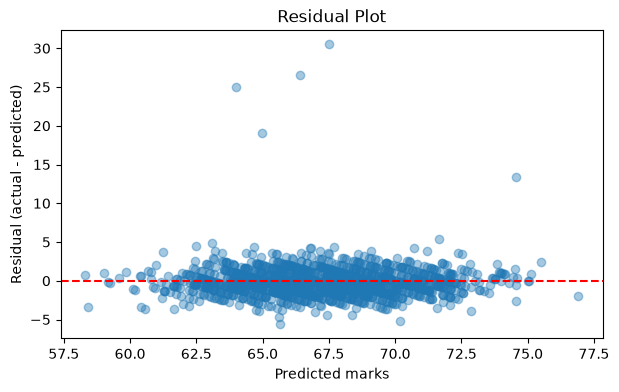

TASK 1 - EXAM MARKS PREDICTION


Enter Study Hours (1-44):  40
Enter Attendance Percentage (60-100):  85
Enter Previous Exam Marks (50-100):  98



--- TASK 1 OUTPUT ---
Predicted Exam Marks: 75.09 / 100
   Exam_Score Result  Result_Label
0          67   Pass             1
1          61   Fail             0
2          74   Pass             1
3          71   Pass             1
4          70   Pass             1

Result
Pass    5154
Fail    1452
Name: count, dtype: int64
Result
Pass    78.0
Fail    22.0
Name: proportion, dtype: float64


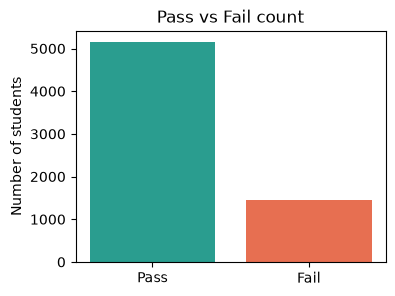

Features used: ['Hours_Studied', 'Attendance', 'Previous_Scores']
X shape: (6606, 3) | y shape: (6606,)
Training rows: 5284
Testing rows : 1322
Pass share in test set: 78.0 %
Model trained
Training accuracy: 0.885
Accuracy : 0.879
Precision: 0.904
Recall   : 0.945
F1 score : 0.924
ROC-AUC  : 0.932
[[188 103]
 [ 57 974]]


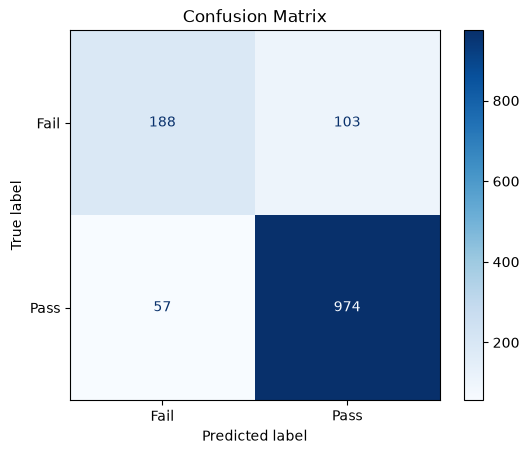

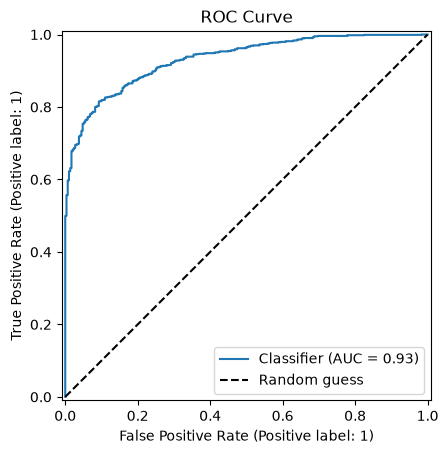

TASK 2 - PASS / FAIL PREDICTION
Student Result         : PASS
Probability of Passing : 100.00%


In [1]:
# TASK 1
import pandas as pd                 
import numpy as np                  
import matplotlib.pyplot as plt  
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

print("ML environment ready")
df = pd.read_csv("StudentPerformanceFactors.csv")
print("Shape (rows, columns):", df.shape)
df.head()
df.info()
print()
df[["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]].describe()
missing = df.isnull().sum()
print("Missing values (only columns that have some):")
print(missing[missing > 0])
print()
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
for col in ["Teacher_Quality", "Parental_Education_Level", "Distance_from_Home"]:
    df[col] = df[col].fillna(df[col].mode()[0])
print("Rows with Exam_Score > 100:", (df["Exam_Score"] > 100).sum())
df = df[df["Exam_Score"] <= 100].reset_index(drop=True)
text_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Text columns (not used as features):", text_columns)
print()
print("Missing values left:", df.isnull().sum().sum())
print("Final shape:", df.shape)
features = ["Hours_Studied", "Attendance", "Previous_Scores"]
X = df[features]          
y = df["Exam_Score"]      
print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)
for name, coef in zip(features, reg_model.coef_):
    print(f"{name:16s} coefficient: {coef:.4f}")
print("Intercept:", round(reg_model.intercept_, 4))
y_pred = reg_model.predict(X_test)
mae  = mean_absolute_error(y_test, y_pred)     
mse  = mean_squared_error(y_test, y_pred)      
rmse = np.sqrt(mse)                            
r2   = r2_score(y_test, y_pred)                
print("MAE :", round(mae, 3))
print("MSE :", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2  :", round(r2, 3))
residuals = y_test - y_pred
plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")      
plt.xlabel("Predicted marks")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual Plot")
plt.show()
print("=" * 50)
print("TASK 1 - EXAM MARKS PREDICTION")
print("=" * 50)
hours = float(input("Enter Study Hours (1-44): "))
attendance = float(input("Enter Attendance Percentage (60-100): "))
previous = float(input("Enter Previous Exam Marks (50-100): "))
if not (1 <= hours <= 44):
    raise ValueError("Study Hours must be between 1 and 44.")
if not (60 <= attendance <= 100):
    raise ValueError("Attendance must be between 60 and 100.")
if not (50 <= previous <= 100):
    raise ValueError("Previous Exam Marks must be between 50 and 100.")
student_data = pd.DataFrame({
    "Hours_Studied": [hours],
    "Attendance": [attendance],
    "Previous_Scores": [previous]
})
predicted_marks = float(reg_model.predict(student_data)[0])
predicted_marks = max(0, min(100, predicted_marks))
print("\n--- TASK 1 OUTPUT ---")
print(f"Predicted Exam Marks: {predicted_marks:.2f} / 100")

#TASK 2
pass_mark = 65
df["Result"] = np.where(df["Exam_Score"] >= pass_mark, "Pass", "Fail")
df["Result_Label"] = (df["Result"] == "Pass").astype(int)
print(df[["Exam_Score", "Result", "Result_Label"]].head())
print()
print(df["Result"].value_counts())
counts = df["Result"].value_counts()
percent = df["Result"].value_counts(normalize=True) * 100
print(percent.round(1))
plt.figure(figsize=(4, 3))
plt.bar(counts.index, counts.values, color=["#2a9d8f", "#e76f51"])
plt.ylabel("Number of students")
plt.title("Pass vs Fail count")
plt.show()
X_cls = df[features]
y_cls = df["Result_Label"]
print("Features used:", list(X_cls.columns))
print("X shape:", X_cls.shape, "| y shape:", y_cls.shape)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)
print("Training rows:", Xc_train.shape[0])
print("Testing rows :", Xc_test.shape[0])
print("Pass share in test set:", round(yc_test.mean() * 100, 1), "%")
clf_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
clf_model.fit(Xc_train, yc_train)
print("Model trained")
print("Training accuracy:", round(clf_model.score(Xc_train, yc_train), 3))
yc_pred = clf_model.predict(Xc_test)
yc_prob = clf_model.predict_proba(Xc_test)[:, 1]  
print("Accuracy :", round(accuracy_score(yc_test, yc_pred), 3))
print("Precision:", round(precision_score(yc_test, yc_pred), 3))
print("Recall   :", round(recall_score(yc_test, yc_pred), 3))
print("F1 score :", round(f1_score(yc_test, yc_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(yc_test, yc_prob), 3))
cm = confusion_matrix(yc_test, yc_pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=["Fail", "Pass"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()
RocCurveDisplay.from_predictions(yc_test, yc_prob)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.legend()
plt.title("ROC Curve")
plt.show()
predicted_class = int(clf_model.predict(student_data)[0])
pass_probability = float(clf_model.predict_proba(student_data)[0, 1]) * 100
result = "PASS" if predicted_class == 1 else "FAIL"
print("=" * 50)
print("TASK 2 - PASS / FAIL PREDICTION")
print("=" * 50)
print(f"Student Result         : {result}")
print(f"Probability of Passing : {pass_probability:.2f}%")

In [ ]:
#TASK 3
POINT                   REGRESSION MODEL                              CLASSIFICATION MODEL
Algorithm used	         Linear Regression	                           Logistic Regression
Target variable	         Exam_Score (marks)	                           Result (Pass = 1, Fail = 0)
Type of prediction	     A continuous number	                       A category (Pass or Fail)
Evaluation metrics	     MAE, MSE, RMSE, R2  (R2 = 0.66, RMSE = 2.13   Accuracy, Precision, Recall, F1, ROC-AUC  (Acc...
Real-world application	 Estimate a student's expected marks	       Flag students at risk of failing